In [48]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [49]:
df=pd.read_excel('PJMW_MW_Hourly (2).xlsx')

In [50]:
print(df.head())

             Datetime  PJMW_MW
0 2002-12-31 01:00:00     5077
1 2002-12-31 02:00:00     4939
2 2002-12-31 03:00:00     4885
3 2002-12-31 04:00:00     4857
4 2002-12-31 05:00:00     4930


In [51]:
print(df.shape)


(143206, 2)


In [52]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 143206 entries, 0 to 143205
Data columns (total 2 columns):
 #   Column    Non-Null Count   Dtype         
---  ------    --------------   -----         
 0   Datetime  143206 non-null  datetime64[ns]
 1   PJMW_MW   143206 non-null  int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 2.2 MB
None


In [53]:
print(df.describe())


                            Datetime        PJMW_MW
count                         143206  143206.000000
mean   2010-06-02 03:39:50.656816128    5602.375089
min              2002-04-01 01:00:00     487.000000
25%              2006-05-02 03:15:00    4907.000000
50%              2010-06-02 04:30:00    5530.000000
75%              2014-07-03 06:45:00    6252.000000
max              2018-08-03 00:00:00    9594.000000
std                              NaN     979.142872


In [54]:

print(df.isnull().sum())

Datetime    0
PJMW_MW     0
dtype: int64


In [55]:
from statsmodels.graphics.tsaplots import plot_acf

In [56]:
df = df.sort_values("Datetime")
df = df.drop_duplicates("Datetime")
df = df.set_index("Datetime")
df = df.asfreq("h")
print("Missing hours:", df["PJMW_MW"].isna().sum())

Missing hours: 30


In [57]:
df.loc[df["PJMW_MW"] < 1500, "PJMW_MW"] = np.nan
df = df.interpolate(method="time")
print("Missing after fixing:", df["PJMW_MW"].isna().sum())

Missing after fixing: 0


In [58]:
print(" FEATURE ENGINEERING")
df["hour"] = df.index.hour
df["day_of_week"] = df.index.dayofweek
df["month"] = df.index.month
df["year"] = df.index.year
df["is_weekend"] = (df["day_of_week"] >= 5).astype(int)

 FEATURE ENGINEERING


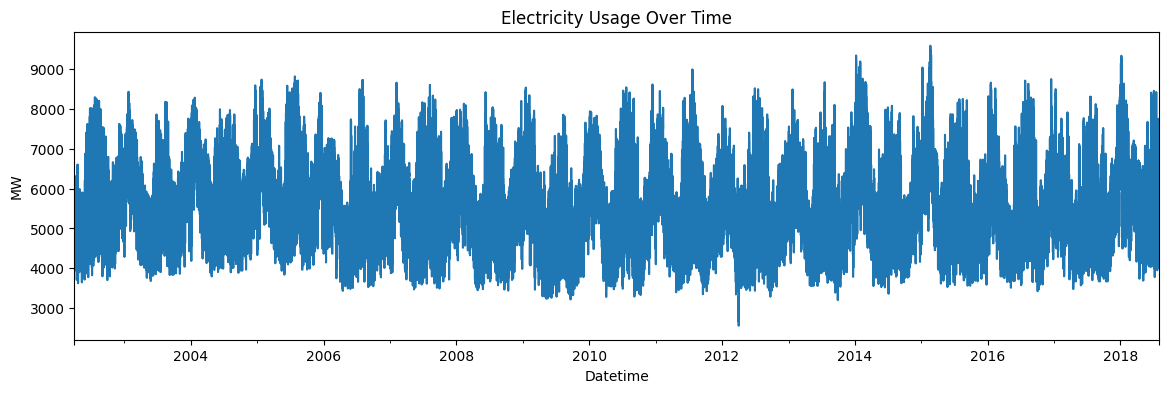

In [59]:
df["PJMW_MW"].plot(figsize=(14, 4))
plt.title("Electricity Usage Over Time")
plt.ylabel("MW")
plt.show()


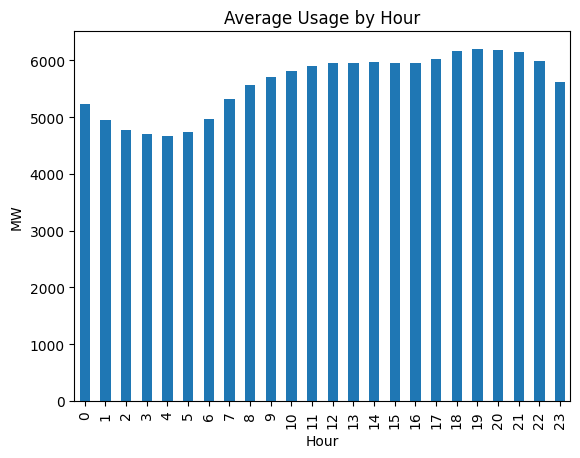

In [60]:
df.groupby("hour")["PJMW_MW"].mean().plot(kind="bar")
plt.title("Average Usage by Hour")
plt.xlabel("Hour")
plt.ylabel("MW")
plt.show()


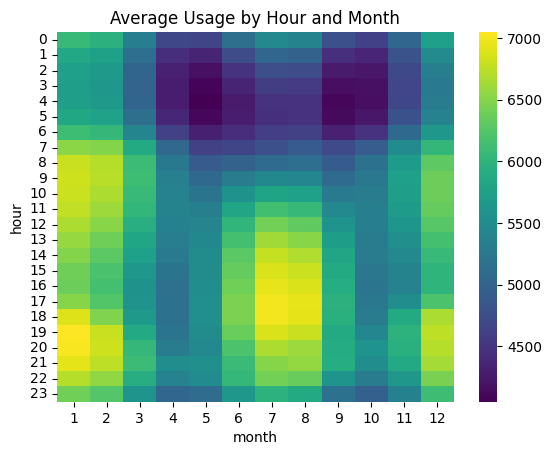

In [61]:
data = df.pivot_table(
    index="hour",
    columns="month",
    values="PJMW_MW"
)

sns.heatmap(data, cmap="viridis")
plt.title("Average Usage by Hour and Month")
plt.show()

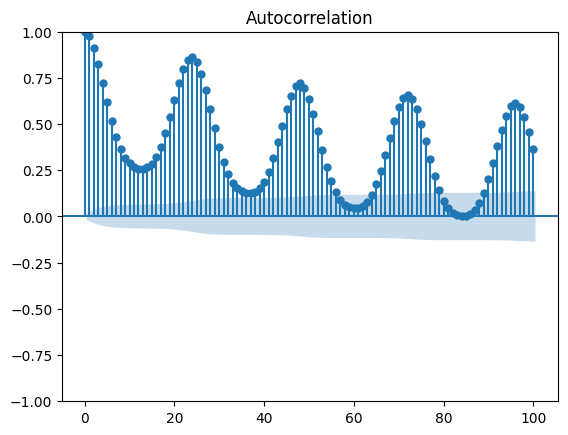

In [62]:
plot_acf(df["PJMW_MW"].loc["2017"], lags=100)
plt.show()


In [63]:
df["hour_sin"] = np.sin(2 * np.pi * df["hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["hour"] / 24)

df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)
df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)

In [64]:
df


,PJMW_MW,hour,day_of_week,month,year,is_weekend,hour_sin,hour_cos,month_sin,month_cos
Datetime,,,,,,,,,,
2002-04-01 01:00:00,4374.0,1,0,4,2002,0,0.258819,0.965926,0.866025,-0.5
2002-04-01 02:00:00,4306.0,2,0,4,2002,0,0.500000,0.866025,0.866025,-0.5
2002-04-01 03:00:00,4322.0,3,0,4,2002,0,0.707107,0.707107,0.866025,-0.5
2002-04-01 04:00:00,4359.0,4,0,4,2002,0,0.866025,0.500000,0.866025,-0.5
2002-04-01 05:00:00,4436.0,5,0,4,2002,0,0.965926,0.258819,0.866025,-0.5
...,...,...,...,...,...,...,...,...,...,...
2018-08-02 20:00:00,6545.0,20,3,8,2018,0,-0.866025,0.500000,-0.866025,-0.5
2018-08-02 21:00:00,6496.0,21,3,8,2018,0,-0.707107,0.707107,-0.866025,-0.5
2018-08-02 22:00:00,6325.0,22,3,8,2018,0,-0.500000,0.866025,-0.866025,-0.5


In [65]:
df["lag_1"] = df["PJMW_MW"].shift(1)
df["lag_24"] = df["PJMW_MW"].shift(24)
df["lag_168"] = df["PJMW_MW"].shift(168)

In [66]:
df

,PJMW_MW,hour,day_of_week,month,year,is_weekend,hour_sin,hour_cos,month_sin,month_cos,lag_1,lag_24,lag_168
Datetime,,,,,,,,,,,,,
2002-04-01 01:00:00,4374.0,1,0,4,2002,0,0.258819,0.965926,0.866025,-0.5,NaN,NaN,NaN
2002-04-01 02:00:00,4306.0,2,0,4,2002,0,0.500000,0.866025,0.866025,-0.5,4374.0,NaN,NaN
2002-04-01 03:00:00,4322.0,3,0,4,2002,0,0.707107,0.707107,0.866025,-0.5,4306.0,NaN,NaN
2002-04-01 04:00:00,4359.0,4,0,4,2002,0,0.866025,0.500000,0.866025,-0.5,4322.0,NaN,NaN
2002-04-01 05:00:00,4436.0,5,0,4,2002,0,0.965926,0.258819,0.866025,-0.5,4359.0,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-08-02 20:00:00,6545.0,20,3,8,2018,0,-0.866025,0.500000,-0.866025,-0.5,6693.0,6816.0,7354.0
2018-08-02 21:00:00,6496.0,21,3,8,2018,0,-0.707107,0.707107,-0.866025,-0.5,6545.0,6571.0,7063.0
2018-08-02 22:00:00,6325.0,22,3,8,2018,0,-0.500000,0.866025,-0.866025,-0.5,6496.0,6362.0,6895.0


In [67]:
df["rolling_24"] = df["PJMW_MW"].shift(1).rolling(24).mean()
df["rolling_168"] = df["PJMW_MW"].shift(1).rolling(168).mean()

In [68]:
df = df.dropna()

In [69]:
print(df.corr()["PJMW_MW"].sort_values(ascending=False))

PJMW_MW        1.000000
lag_1          0.974841
lag_24         0.877320
lag_168        0.759970
rolling_24     0.723301
rolling_168    0.583917
hour           0.447339
month_cos      0.193141
month_sin      0.105318
year          -0.047368
month         -0.152651
day_of_week   -0.203208
hour_cos      -0.233921
is_weekend    -0.245884
hour_sin      -0.422122
Name: PJMW_MW, dtype: float64


In [70]:
df

,PJMW_MW,hour,day_of_week,month,year,is_weekend,hour_sin,hour_cos,month_sin,month_cos,lag_1,lag_24,lag_168,rolling_24,rolling_168
Datetime,,,,,,,,,,,,,,,
2002-04-08 01:00:00,4634.0,1,0,4,2002,0,0.258819,0.965926,0.866025,-0.5,4798.0,5002.0,4374.0,5039.229167,5380.711310
2002-04-08 02:00:00,4532.0,2,0,4,2002,0,0.500000,0.866025,0.866025,-0.5,4634.0,4858.0,4306.0,5023.895833,5382.258929
2002-04-08 03:00:00,4481.0,3,0,4,2002,0,0.707107,0.707107,0.866025,-0.5,4532.0,4864.5,4322.0,5010.312500,5383.604167
2002-04-08 04:00:00,4527.0,4,0,4,2002,0,0.866025,0.500000,0.866025,-0.5,4481.0,4871.0,4359.0,4994.333333,5384.550595
2002-04-08 05:00:00,4640.0,5,0,4,2002,0,0.965926,0.258819,0.866025,-0.5,4527.0,4909.0,4436.0,4980.000000,5385.550595
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2018-08-02 20:00:00,6545.0,20,3,8,2018,0,-0.866025,0.500000,-0.866025,-0.5,6693.0,6816.0,7354.0,5820.541667,5681.827381
2018-08-02 21:00:00,6496.0,21,3,8,2018,0,-0.707107,0.707107,-0.866025,-0.5,6545.0,6571.0,7063.0,5809.250000,5677.011905
2018-08-02 22:00:00,6325.0,22,3,8,2018,0,-0.500000,0.866025,-0.866025,-0.5,6496.0,6362.0,6895.0,5806.125000,5673.636905


Model Building


In [71]:

test_hours = 24 * 14
train = df.iloc[:-test_hours]
test = df.iloc[-test_hours:]

In [72]:
X_train = train.drop(columns="PJMW_MW")
y_train = train["PJMW_MW"]
X_test = test.drop(columns="PJMW_MW")
y_test = test["PJMW_MW"]

In [73]:

print("Train size:", X_train.shape)
print("Test size (last 14 days):", X_test.shape)

Train size: (142728, 14)
Test size (last 14 days): (336, 14)


In [74]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [75]:
dt = DecisionTreeRegressor(max_depth=10, random_state=1)
dt.fit(X_train, y_train)
dt_pred = dt.predict(X_test)

In [76]:
rf = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)
rf_pred = rf.predict(X_test)

In [77]:
xgb = XGBRegressor(n_estimators=300, learning_rate=0.1, max_depth=6, random_state=1)
xgb.fit(X_train, y_train)
xgb_pred = xgb.predict(X_test)

In [78]:
series = df["PJMW_MW"]
ts_train = series.iloc[-test_hours - 24 * 60:-test_hours]
ts_test = series.iloc[-test_hours:]
 
arima_fit = ARIMA(ts_train, order=(2, 1, 2)).fit()
sarima_fit = SARIMAX(ts_train, order=(1, 1, 1), seasonal_order=(1, 1, 1, 24)).fit(disp=False)

c:\Users\sahar\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:966: UserWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  warn('Non-stationary starting autoregressive parameters'
c:\Users\sahar\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\tsa\statespace\sarimax.py:978: UserWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  warn('Non-invertible starting MA parameters found.'


In [79]:
arima_pred = []
sarima_pred = []
arima_model = arima_fit
sarima_model = sarima_fit
 
for i in range(len(ts_test)):
    arima_pred.append(arima_model.forecast(1).iloc[0])
    sarima_pred.append(sarima_model.forecast(1).iloc[0])
    new_value = ts_test.iloc[i:i + 1]
    arima_model = arima_model.extend(new_value)
    sarima_model = sarima_model.extend(new_value)

In [80]:
predictions = {
    "ARIMA": np.array(arima_pred),
    "SARIMA": np.array(sarima_pred),
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
}
 
rows = []
for name, pred in predictions.items():
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    mape = np.mean(np.abs((y_test.values - pred) / y_test.values)) * 100
    r2 = r2_score(y_test, pred)
    rows.append([name, mae, rmse, mape, r2])
 
results = pd.DataFrame(rows, columns=["Model", "MAE", "RMSE", "MAPE %", "R2"])
print(results.round(3))

           Model     MAE     RMSE  MAPE %     R2
0          ARIMA  69.234   91.454   1.247  0.990
1         SARIMA  55.108   70.659   0.983  0.994
2  Decision Tree  79.159  103.486   1.381  0.987
3  Random Forest  53.248   67.372   0.929  0.994
4        XGBoost  53.271   66.923   0.935  0.995


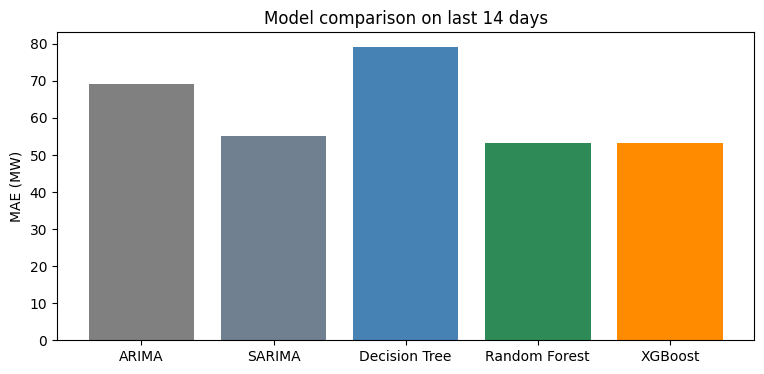

In [81]:
plt.figure(figsize=(9, 4))
plt.bar(results["Model"], results["MAE"], color=["gray", "slategray", "steelblue", "seagreen", "darkorange"])
plt.title("Model comparison on last 14 days")
plt.ylabel("MAE (MW)")
plt.show()

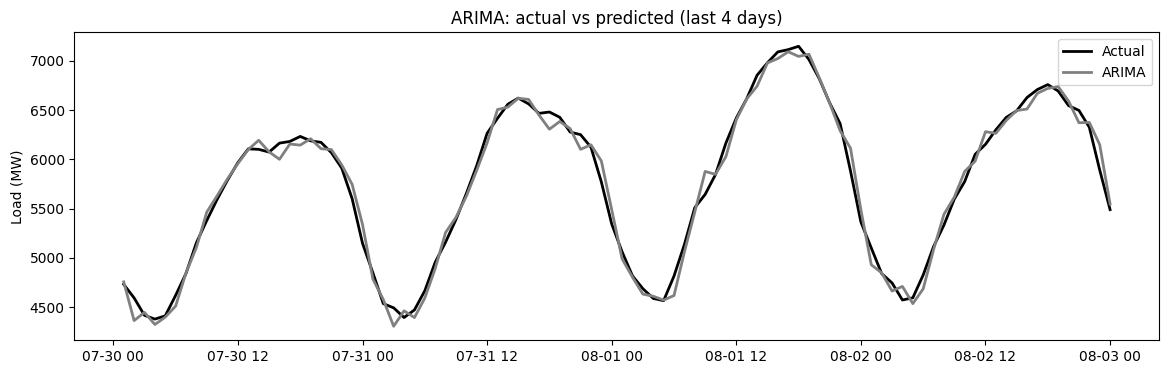

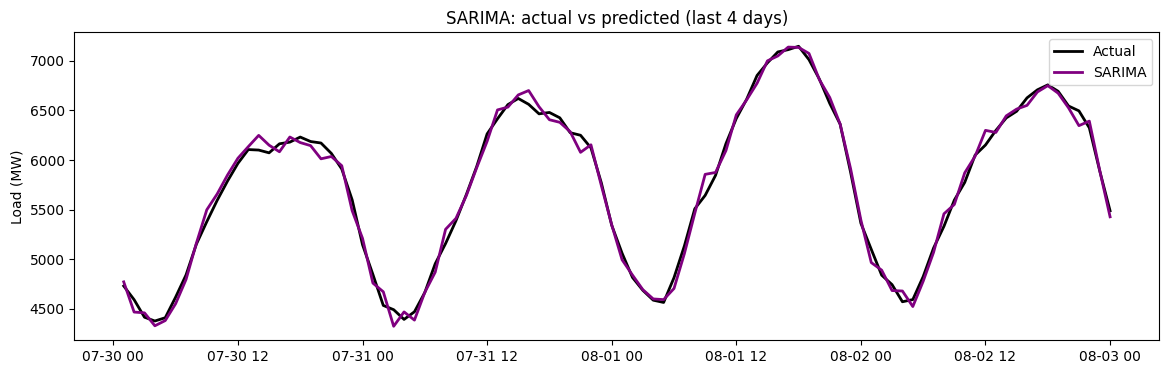

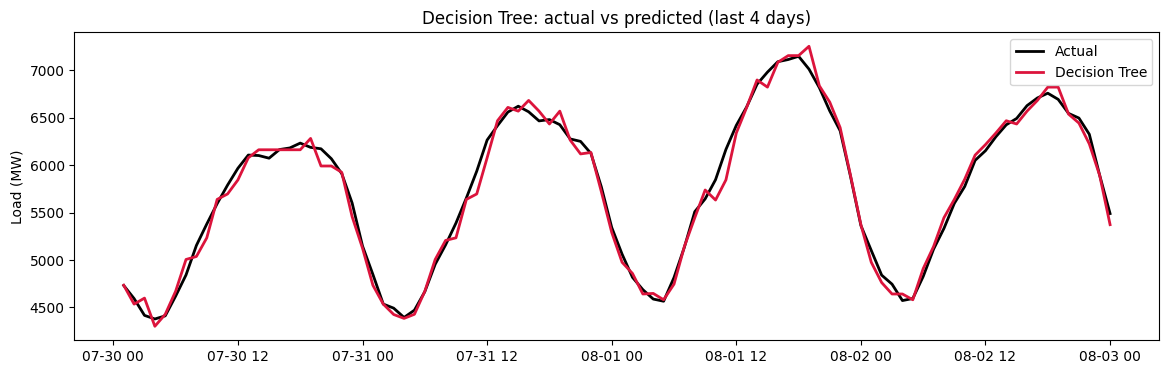

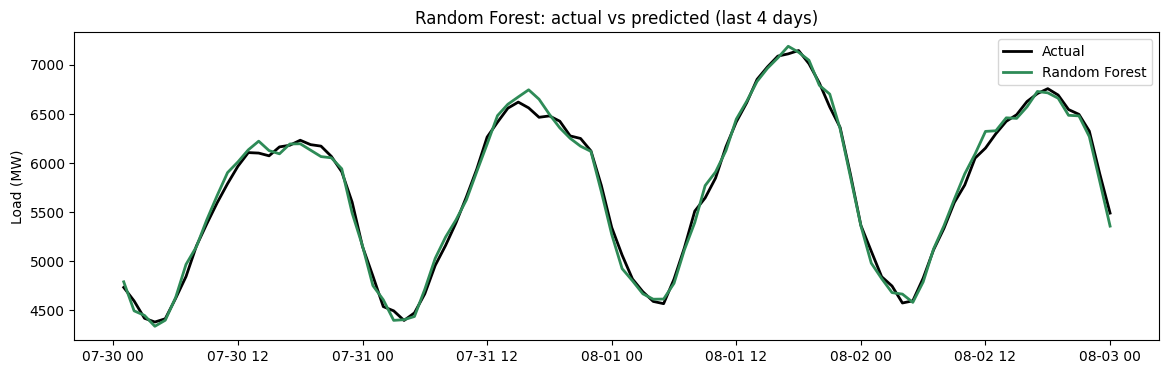

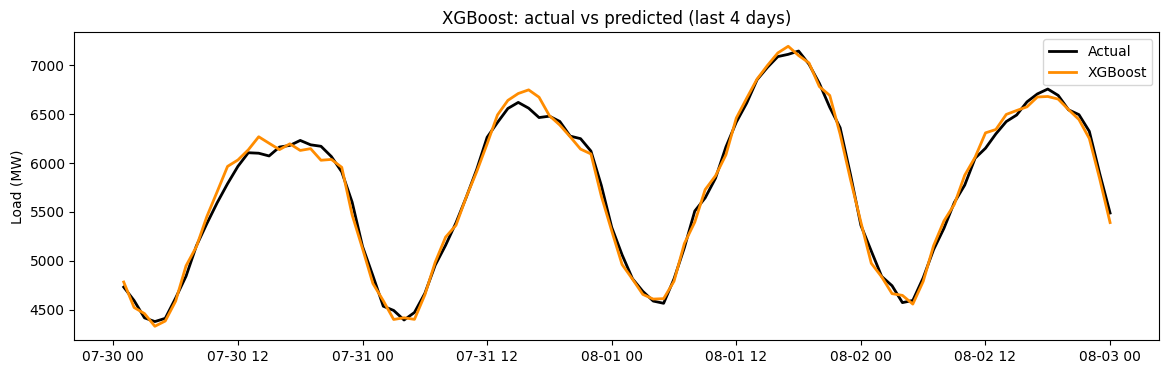

In [82]:
colors = {"ARIMA": "gray", "SARIMA": "purple", "Decision Tree": "crimson", "Random Forest": "seagreen", "XGBoost": "darkorange"}

for name, pred in predictions.items():
    plt.figure(figsize=(14, 4))
    plt.plot(y_test.index[-96:], y_test.iloc[-96:], label="Actual", color="black", linewidth=2)
    plt.plot(y_test.index[-96:], pred[-96:], label=name, color=colors[name], linewidth=2)
    plt.title(name + ": actual vs predicted (last 4 days)")
    plt.ylabel("Load (MW)")
    plt.legend()
    plt.show()

In [83]:

naive_mae = mean_absolute_error(y_test, X_test["lag_1"])
print("Naive MAE (just repeat last hour):", round(naive_mae, 1))
results["Better than naive %"] = (1 - results["MAE"] / naive_mae) * 100
print(results[["Model", "MAE", "Better than naive %"]].round(1))

Naive MAE (just repeat last hour): 195.8
           Model   MAE  Better than naive %
0          ARIMA  69.2                 64.6
1         SARIMA  55.1                 71.9
2  Decision Tree  79.2                 59.6
3  Random Forest  53.2                 72.8
4        XGBoost  53.3                 72.8


ARIMA            0.6
SARIMA          -0.0
Decision Tree   -9.0
Random Forest    3.4
XGBoost          4.8
dtype: float64


C:\Users\sahar\AppData\Local\Temp\ipykernel_15352\2379727683.py:5: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([errors[c] for c in errors.columns], labels=errors.columns)


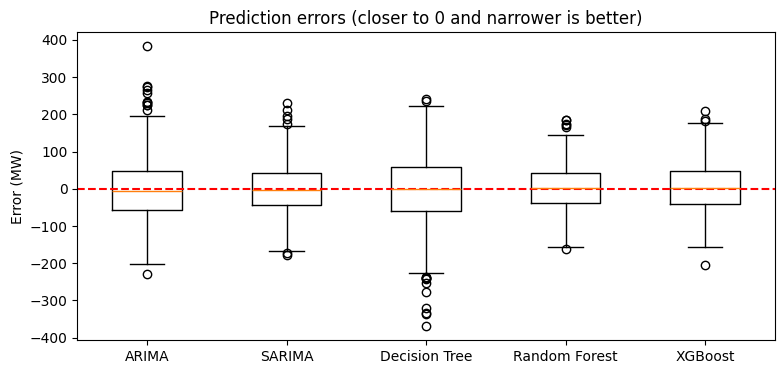

In [84]:
errors = pd.DataFrame({name: pred - y_test.values for name, pred in predictions.items()}, index=y_test.index)
print(errors.mean().round(1))
 
plt.figure(figsize=(9, 4))
plt.boxplot([errors[c] for c in errors.columns], labels=errors.columns)
plt.axhline(0, color="red", linestyle="--")
plt.title("Prediction errors (closer to 0 and narrower is better)")
plt.ylabel("Error (MW)")
plt.show()
 

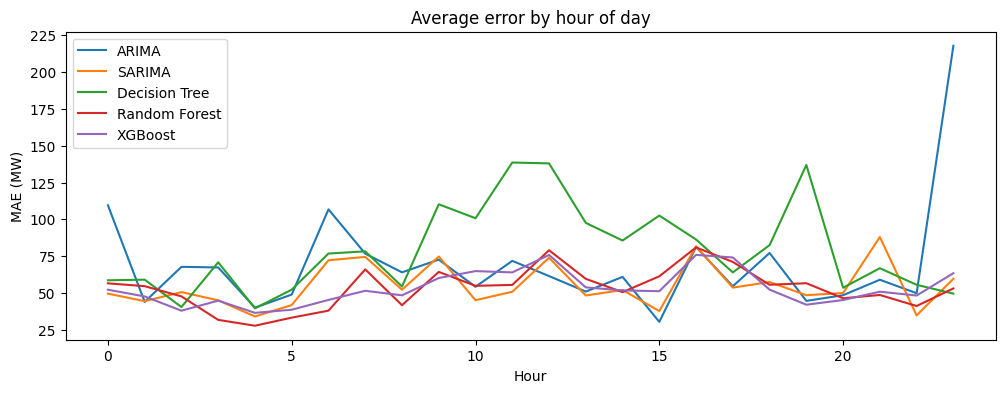

In [85]:
errors.abs().groupby(errors.index.hour).mean().plot(figsize=(12, 4), title="Average error by hour of day")
plt.ylabel("MAE (MW)")
plt.xlabel("Hour")
plt.show()

In [86]:
print(results.sort_values("RMSE").round(3))
print("Best model by RMSE:", results.sort_values("RMSE").iloc[0]["Model"])

           Model     MAE     RMSE  MAPE %     R2  Better than naive %
4        XGBoost  53.271   66.923   0.935  0.995               72.791
3  Random Forest  53.248   67.372   0.929  0.994               72.803
1         SARIMA  55.108   70.659   0.983  0.994               71.853
0          ARIMA  69.234   91.454   1.247  0.990               64.638
2  Decision Tree  79.159  103.486   1.381  0.987               59.568
Best model by RMSE: XGBoost


In [87]:
naive_mae = mean_absolute_error(y_test, X_test["lag_1"])
print("Naive MAE:", round(naive_mae, 1))
for name, pred in predictions.items():
    mae = mean_absolute_error(y_test, pred)
    print(name, "MAE:", round(mae, 1), "| better than naive by", round((1 - mae / naive_mae) * 100), "%")

Naive MAE: 195.8
ARIMA MAE: 69.2 | better than naive by 65 %
SARIMA MAE: 55.1 | better than naive by 72 %
Decision Tree MAE: 79.2 | better than naive by 60 %
Random Forest MAE: 53.2 | better than naive by 73 %
XGBoost MAE: 53.3 | better than naive by 73 %


In [88]:
for name, model in [("Decision Tree", dt), ("Random Forest", rf), ("XGBoost", xgb)]:
    train_mae = mean_absolute_error(y_train, model.predict(X_train))
    test_mae = mean_absolute_error(y_test, model.predict(X_test))
    print(name, "| train MAE:", round(train_mae, 1), "| test MAE:", round(test_mae, 1))

Decision Tree | train MAE: 80.1 | test MAE: 79.2
Random Forest | train MAE: 38.1 | test MAE: 53.2
XGBoost | train MAE: 47.5 | test MAE: 53.3


In [89]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense
from tensorflow.keras.callbacks import EarlyStopping

In [90]:
from sklearn.preprocessing import MinMaxScaler

Epoch 1/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0589
Epoch 2/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0296
Epoch 3/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0117
Epoch 4/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0048
Epoch 5/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0041
Epoch 6/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0037
Epoch 7/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0033
Epoch 8/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0030
Epoch 9/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0028
Epoch 10/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0026
Epoch 11/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0024
Epoch 12/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0022
Epoch 13/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0020
Epoch 14/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0019
Epoch 15/30
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0018
Epoch 16/30
45/45 ━

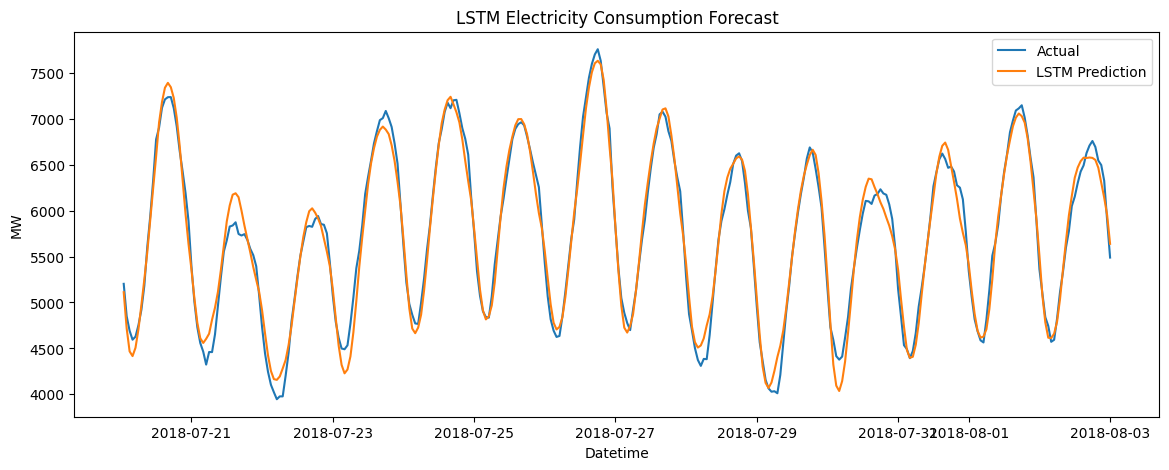

In [91]:
scaler = MinMaxScaler()
scaler.fit(ts_train.to_numpy().reshape(-1, 1))

train_scaled = scaler.transform(
    ts_train.to_numpy().reshape(-1, 1)
).flatten()

history = list(train_scaled)
lookback = 24

X_train = []
y_train = []

for i in range(lookback, len(train_scaled)):
    X_train.append(train_scaled[i - lookback:i])
    y_train.append(train_scaled[i])

X_train = np.array(X_train).reshape(-1, lookback, 1)
y_train = np.array(y_train)

lstm_model = Sequential([
    Input(shape=(lookback, 1)),
    LSTM(50),
    Dense(1)
])

lstm_model.compile(optimizer="adam", loss="mse")

lstm_model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    shuffle=False,
    verbose=1
)

lstm_pred = []

for i in range(len(ts_test)):
    X = np.array(history[-lookback:]).reshape(1, lookback, 1)

    pred = lstm_model.predict(X, verbose=0)[0, 0]
    lstm_pred.append(pred)

    actual_value = scaler.transform(
        ts_test.iloc[i:i + 1].to_numpy().reshape(-1, 1)
    )[0, 0]

    history.append(actual_value)

lstm_pred = scaler.inverse_transform(
    np.array(lstm_pred).reshape(-1, 1)
).flatten()

actual = ts_test.to_numpy()

print("LSTM MAE:", mean_absolute_error(actual, lstm_pred))
print("LSTM RMSE:", np.sqrt(mean_squared_error(actual, lstm_pred)))

plt.figure(figsize=(14, 5))
plt.plot(ts_test.index, actual, label="Actual")
plt.plot(ts_test.index, lstm_pred, label="LSTM Prediction")
plt.title("LSTM Electricity Consumption Forecast")
plt.xlabel("Datetime")
plt.ylabel("MW")
plt.legend()
plt.show()


    Model      MAE     RMSE  MAPE (%)
0   ARIMA   69.234   91.454     1.247
1  SARIMA   55.108   70.659     0.983
2    LSTM  113.053  143.103     2.077


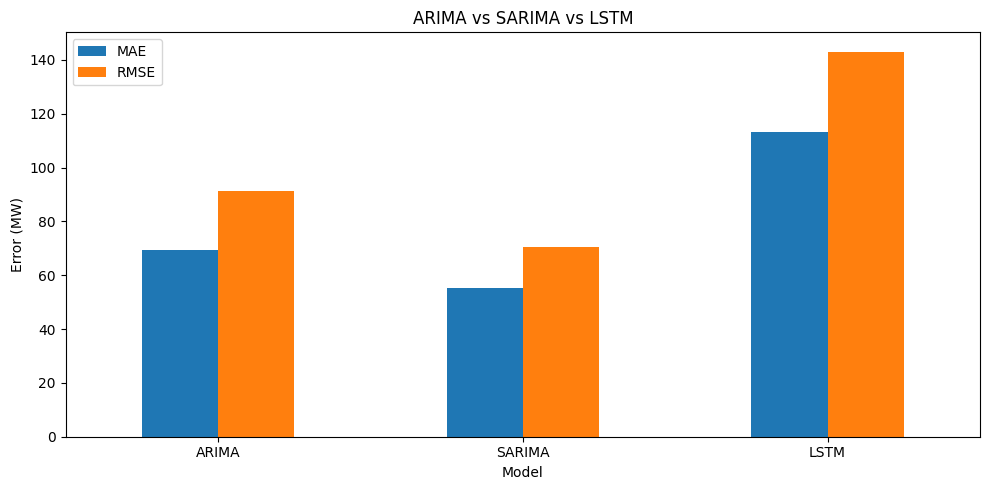

In [92]:
results = []

for name, pred in [
    ("ARIMA", arima_pred),
    ("SARIMA", sarima_pred),
    ("LSTM", lstm_pred)
]:
    pred = np.array(pred)

    mae = mean_absolute_error(actual, pred)
    rmse = np.sqrt(mean_squared_error(actual, pred))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100

    results.append({
        "Model": name,
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    })

results_df = pd.DataFrame(results)
print(results_df.round(3))

results_df.set_index("Model")[["MAE", "RMSE"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("ARIMA vs SARIMA vs LSTM")
plt.ylabel("Error (MW)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [93]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = ts_test.to_numpy()

predictions = {
    "ARIMA": arima_pred,
    "SARIMA": sarima_pred,
    "LSTM": lstm_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "XGBoost": xgb_pred,
}

results = []

for name, pred in predictions.items():
    pred = np.array(pred).flatten()

    if len(pred) != len(actual):
        print(f"Skipping {name}: prediction length mismatch")
        continue

    results.append({
        "Model": name,
        "MAE": mean_absolute_error(actual, pred),
        "RMSE": np.sqrt(mean_squared_error(actual, pred)),
        "MAPE (%)": np.mean(np.abs((actual - pred) / actual)) * 100
    })

results_df = pd.DataFrame(results).sort_values("RMSE")

print(results_df.round(3).to_string(index=False))


        Model     MAE    RMSE  MAPE (%)
      XGBoost  53.271  66.923     0.935
Random Forest  53.248  67.372     0.929
       SARIMA  55.108  70.659     0.983
        ARIMA  69.234  91.454     1.247
Decision Tree  79.159 103.486     1.381
         LSTM 113.053 143.103     2.077


In [94]:
import joblib
joblib.dump(xgb, "xgboost_model.pkl")

['xgboost_model.pkl']